In [1]:
# Get thresholds calculated from training data
t50 = thresholds.loc[0.50]
t75 = thresholds.loc[0.75]
t90 = thresholds.loc[0.90]

# Assign traffic-load categories
def classify_traffic(value):
    if value <= t50:
        return "Normal"
    elif value <= t75:
        return "Moderate"
    elif value <= t90:
        return "High"
    else:
        return "Potential Congestion"

df["traffic_status"] = df["internet"].apply(classify_traffic)

print("Traffic category distribution:")
print(df["traffic_status"].value_counts())

print("\nSample classified records:")
display(
    df[["GridID", "datetime", "internet", "traffic_status"]]
    .head(10)
)

NameError: name 'thresholds' is not defined

In [2]:
import pandas as pd
import numpy as np

# Load feature-engineered dataset
df = pd.read_csv(
    "../data/traffic_features.csv",
    parse_dates=["datetime"]
)

# Sort chronologically
df = df.sort_values(
    ["datetime", "GridID"]
).reset_index(drop=True)

# Get unique timestamps
timestamps = np.sort(df["datetime"].unique())

# Use first 70% of timestamps for training
train_end = int(len(timestamps) * 0.70)

train_times = timestamps[:train_end]

train_df = df[
    df["datetime"].isin(train_times)
].copy()

# Calculate thresholds from training data only
thresholds = train_df["internet"].quantile(
    [0.50, 0.75, 0.90]
)

print("Dataset shape:", df.shape)

print("\nTraffic thresholds:")
print(thresholds)

Dataset shape: (20880, 19)

Traffic thresholds:
0.50    15.030232
0.75    22.683799
0.90    30.843501
Name: internet, dtype: float64


In [3]:
# Extract thresholds
t50 = thresholds.loc[0.50]
t75 = thresholds.loc[0.75]
t90 = thresholds.loc[0.90]

# Define traffic classification function
def classify_traffic(value):
    if value <= t50:
        return "Normal"
    elif value <= t75:
        return "Moderate"
    elif value <= t90:
        return "High"
    else:
        return "Potential Congestion"

# Create classification labels
df["traffic_status"] = df["internet"].apply(classify_traffic)

# Display category distribution
print("=== Traffic Category Distribution ===")
print(df["traffic_status"].value_counts())

print("\n=== Sample Classified Records ===")
display(
    df[["GridID", "datetime", "internet", "traffic_status"]]
    .head(10)
)

=== Traffic Category Distribution ===
traffic_status
Normal                  10174
Moderate                 5316
High                     3235
Potential Congestion     2155
Name: count, dtype: int64

=== Sample Classified Records ===


,GridID,datetime,internet,traffic_status
0,1,2013-11-01 23:00:00+00:00,7.837850,Normal
1,100,2013-11-01 23:00:00+00:00,5.360477,Normal
2,1000,2013-11-01 23:00:00+00:00,11.912091,Normal
3,5000,2013-11-01 23:00:00+00:00,11.141011,Normal
4,10000,2013-11-01 23:00:00+00:00,14.611517,Normal
5,1,2013-11-01 23:10:00+00:00,8.621555,Normal
6,100,2013-11-01 23:10:00+00:00,6.634849,Normal
7,1000,2013-11-01 23:10:00+00:00,13.976912,Normal
8,5000,2013-11-01 23:10:00+00:00,27.182947,High
9,10000,2013-11-01 23:10:00+00:00,13.659596,Normal


In [4]:
# Get unique timestamps in chronological order
timestamps = np.sort(df["datetime"].unique())

# Calculate split boundaries
train_end = int(len(timestamps) * 0.70)
val_end = int(len(timestamps) * 0.85)

# Create chronological datasets
train_df = df[
    df["datetime"].isin(timestamps[:train_end])
].copy()

val_df = df[
    df["datetime"].isin(timestamps[train_end:val_end])
].copy()

test_df = df[
    df["datetime"].isin(timestamps[val_end:])
].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining category distribution:")
print(train_df["traffic_status"].value_counts())

Training shape: (14615, 20)
Validation shape: (3130, 20)
Testing shape: (3135, 20)

Training category distribution:
traffic_status
Normal                  7308
Moderate                3653
High                    2192
Potential Congestion    1462
Name: count, dtype: int64


In [5]:
from sklearn.ensemble import RandomForestClassifier

# Historical and time-based features
features = [
    "GridID",
    "hour",
    "day_of_week",
    "is_weekend",
    "minute_slot",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_144",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_144",
    "rolling_std_144"
]

# Prepare training and validation data
X_train = train_df[features]
y_train = train_df["traffic_status"]

X_val = val_df[features]
y_val = val_df["traffic_status"]

# Initialize classifier
rf_classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_classifier.fit(X_train, y_train)

# Predict validation categories
y_val_pred = rf_classifier.predict(X_val)

print("Random Forest Classifier trained successfully!")

print("\nFirst 10 predictions:")
print(y_val_pred[:10])

Random Forest Classifier trained successfully!

First 10 predictions:
['Normal' 'Moderate' 'Normal' 'Moderate' 'Moderate' 'Normal' 'Moderate'
 'Normal' 'Moderate' 'Moderate']


In [6]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_val_pred)

print("=== Random Forest Classification Results ===")
print(f"Accuracy: {accuracy:.4f}")

# Detailed performance for each category
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
labels = [
    "Normal",
    "Moderate",
    "High",
    "Potential Congestion"
]

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred,
        labels=labels
    )
)

=== Random Forest Classification Results ===
Accuracy: 0.7783

Classification Report:
                      precision    recall  f1-score   support

                High     0.5582    0.6430    0.5976       507
            Moderate     0.6747    0.6572    0.6659       849
              Normal     0.9124    0.9143    0.9134      1424
Potential Congestion     0.8562    0.7143    0.7788       350

            accuracy                         0.7783      3130
           macro avg     0.7504    0.7322    0.7389      3130
        weighted avg     0.7843    0.7783    0.7800      3130


Confusion Matrix:
[[1302  121    1    0]
 [ 115  558  172    4]
 [   8  135  326   38]
 [   2   13   85  250]]


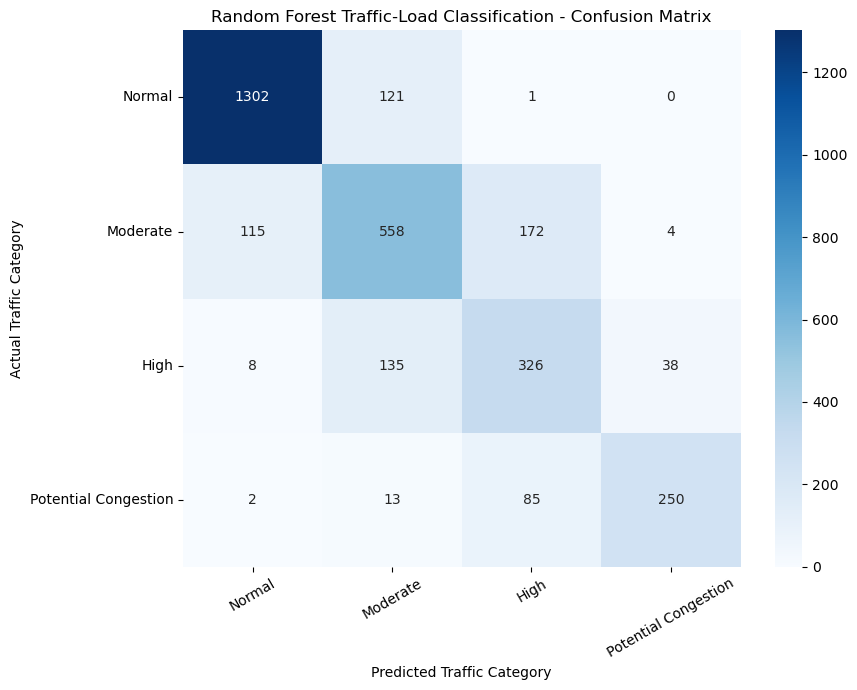

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = [
    "Normal",
    "Moderate",
    "High",
    "Potential Congestion"
]

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Traffic-Load Classification - Confusion Matrix")
plt.xlabel("Predicted Traffic Category")
plt.ylabel("Actual Traffic Category")
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Prepare test features and labels
X_test = test_df[features]
y_test = test_df["traffic_status"]

# Predict traffic categories
y_test_pred = rf_classifier.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

print("=== FINAL CLASSIFICATION TEST RESULTS ===")
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred,
        labels=[
            "Normal",
            "Moderate",
            "High",
            "Potential Congestion"
        ]
    )
)

=== FINAL CLASSIFICATION TEST RESULTS ===
Test Accuracy: 0.7774

Classification Report:
                      precision    recall  f1-score   support

                High     0.5800    0.6287    0.6034       536
            Moderate     0.6724    0.6732    0.6728       814
              Normal     0.9159    0.9216    0.9188      1442
Potential Congestion     0.7743    0.6501    0.7068       343

            accuracy                         0.7774      3135
           macro avg     0.7357    0.7184    0.7254      3135
        weighted avg     0.7798    0.7774    0.7778      3135


Confusion Matrix:
[[1329  112    1    0]
 [ 114  548  146    6]
 [   6  134  337   59]
 [   2   21   97  223]]


In [9]:
import joblib
import os

# Create models directory if needed
os.makedirs("../models", exist_ok=True)

# Save the trained classifier
joblib.dump(
    rf_classifier,
    "../models/traffic_classifier.pkl"
)

# Save the training-based traffic thresholds
joblib.dump(
    {
        "Normal": float(t50),
        "Moderate": float(t75),
        "High": float(t90)
    },
    "../models/traffic_thresholds.pkl"
)

print("Classification model and thresholds saved successfully!")

Classification model and thresholds saved successfully!


In [10]:
import pandas as pd
from sklearn.metrics import classification_report

# Generate final classification metrics
report = classification_report(
    y_test,
    y_test_pred,
    output_dict=True,
    zero_division=0
)

# Convert report into a DataFrame
classification_results = pd.DataFrame(report).transpose()

# Save results
classification_results.to_csv(
    "../outputs/classification_test_results.csv"
)

print("Classification test results saved successfully!")

display(classification_results.round(4))

Classification test results saved successfully!


,precision,recall,f1-score,support
High,0.5800,0.6287,0.6034,536.0000
Moderate,0.6724,0.6732,0.6728,814.0000
Normal,0.9159,0.9216,0.9188,1442.0000
Potential Congestion,0.7743,0.6501,0.7068,343.0000
accuracy,0.7774,0.7774,0.7774,0.7774
macro avg,0.7357,0.7184,0.7254,3135.0000
weighted avg,0.7798,0.7774,0.7778,3135.0000
